In [8]:
from pathlib import Path
import pymupdf

PDF_PATH = Path("./pdfs/attention is all you need.pdf")

OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

if not PDF_PATH.is_file():
    raise FileNotFoundError(
        f"Fichier introuvable : {PDF_PATH.resolve()}"
    )

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDF : {PDF_PATH.resolve()}")
print(f"Résultats : {OUTPUT_DIR.resolve()}")

PDF : C:\Users\HP\RAG-Multimodal-Agentique\pdfs\attention is all you need.pdf
Résultats : C:\Users\HP\RAG-Multimodal-Agentique\resultats_pdf


In [9]:
textes = []
nombre_images = 0
pages_sans_texte = []

with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)

    for numero_page, page in enumerate(document, start=1):

        # ---- Extraction du texte ----
        texte = page.get_text("text", sort=True)

        fichier_texte = TEXT_DIR / f"page_{numero_page:03d}.txt"
        fichier_texte.write_text(texte, encoding="utf-8")

        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # ---- Extraction des images intégrées ----
        images_vues = set()

        for image_info in page.get_images(full=True):
            xref = image_info[0]

            if xref in images_vues:
                continue

            images_vues.add(xref)

            try:
                image = document.extract_image(xref)

                if not image:
                    print(
                        f"Image non extractible : "
                        f"page {numero_page}, xref {xref}"
                    )
                    continue

                extension = image["ext"]

                fichier_image = (
                    IMAGE_DIR
                    / f"page_{numero_page:03d}_image_{xref}.{extension}"
                )

                fichier_image.write_bytes(image["image"])

                nombre_images += 1

            except Exception as erreur:
                print(
                    f"Erreur d'extraction : page {numero_page}, "
                    f"image {xref} : {erreur}"
                )

# Enregistrer le texte de tout le document
(OUTPUT_DIR / "texte_complet.txt").write_text(
    "\n\n".join(textes),
    encoding="utf-8"
)

print(f"Pages traitées : {nombre_pages}")
print(f"Images enregistrées : {nombre_images}")

if pages_sans_texte:
    print("Pages sans texte détectable :", pages_sans_texte)
    print("Si elles contiennent du texte scanné, utilisez l'OCR ci-dessous.")

Pages traitées : 11
Images enregistrées : 3


APERÇU DU TEXTE

===== PAGE 1 =====

             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                         illia.polosukhin@gmail.com


                                Abstract

       The dominant sequence transduction models are based on complex recurrent or
        convolutional neural networks that include an encoder and a decoder. The best
        performing models also connect the encoder and decoder through an attention
       mechanism. We propose a new sim

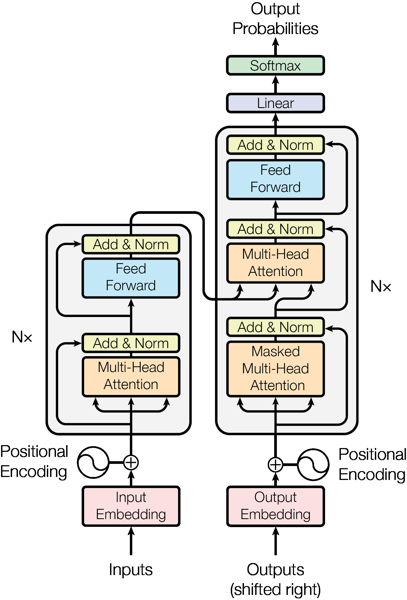

page_004_image_102.png


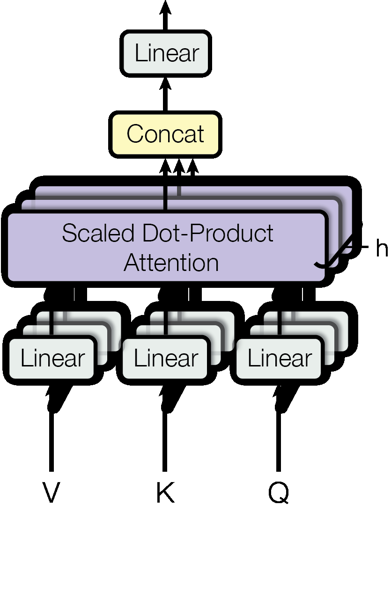

page_004_image_104.png


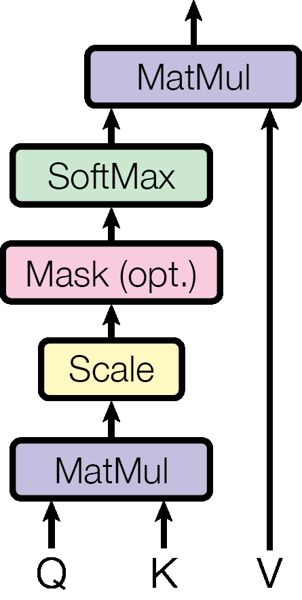

In [10]:
from PIL import Image
from IPython.display import display

texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(
    encoding="utf-8"
)

print("APERÇU DU TEXTE\n")
print(texte_complet[:2000])

print("\nAPERÇU DES IMAGES\n")

for fichier in sorted(IMAGE_DIR.iterdir())[:5]:
    print(fichier.name)

    with Image.open(fichier) as image:
        apercu = image.copy()
        apercu.thumbnail((600, 600))
        display(apercu)

In [12]:
#Vectorisation avec CLIP


In [14]:
import torch
import open_clip
import re
import numpy as np

from pathlib import Path
from PIL import Image
from open_clip.tokenizer import SimpleTokenizer

In [15]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)

model = model.to(DEVICE).eval()

tokenizer = open_clip.get_tokenizer(MODEL_NAME)

bpe = SimpleTokenizer()

print("Appareil utilisé :", DEVICE)
print("Modèle chargé :", MODEL_NAME)
print("Poids préentraînés :", PRETRAINED)

c:\Users\HP\RAG-Multimodal-Agentique\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

c:\Users\HP\RAG-Multimodal-Agentique\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--laion--CLIP-ViT-B-32-laion2B-s34B-b79K. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Appareil utilisé : cpu
Modèle chargé : ViT-B-32
Poids préentraînés : laion2b_s34b_b79k


In [17]:
texte_test = "The Transformer uses attention mechanisms."

tokens_bpe = bpe.encode(texte_test)

tokens = tokenizer([texte_test])

print("Texte original :", texte_test)
print("Tokens BPE :", tokens_bpe)
print("Nombre de tokens BPE :", len(tokens_bpe))
print("Tenseur :", tokens)
print("Dimensions :", tokens.shape)

Texte original : The Transformer uses attention mechanisms.
Tokens BPE : [518, 38235, 5282, 4936, 28610, 269]
Nombre de tokens BPE : 6
Tenseur : tensor([[49406,   518, 38235,  5282,  4936, 28610,   269, 49407,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0]])
Dimensions : torch.Size([1, 77])


In [19]:
#CHUNKING
def decouper_texte(texte, chunk_size=60, overlap=10):

    if not 0 <= overlap < chunk_size <= 75:
        raise ValueError("Paramètres de chunking invalides")

    # Nettoyage du texte
    texte = re.sub(r"\s+", " ", texte).strip()

    # Conversion du texte en tokens BPE
    ids_tokens = bpe.encode(texte)

    chunks = []

    pas = chunk_size - overlap

    # Découpage avec chevauchement
    for debut in range(0, len(ids_tokens), pas):

        fin = debut + chunk_size

        tokens_chunk = ids_tokens[debut:fin]

        chunk = bpe.decode(tokens_chunk).strip()

        if chunk:
            chunks.append(chunk)

        if fin >= len(ids_tokens):
            break

    return chunks

In [20]:
TEXT_DIR = Path("resultats_pdf/textes")

chunks_textes = []

for fichier in sorted(TEXT_DIR.glob("page_*.txt")):

    numero_page = int(fichier.stem.split("_")[-1])

    texte = fichier.read_text(encoding="utf-8")

    chunks = decouper_texte(texte)

    for numero_chunk, chunk in enumerate(chunks, start=1):

        chunks_textes.append({
            "type": "text",
            "page": numero_page,
            "chunk_id": numero_chunk,
            "texte": chunk,
            "source": str(fichier)
        })

    print(f"Page {numero_page} : {len(chunks)} chunks")

print("\nNombre total de chunks :", len(chunks_textes))

Page 1 : 13 chunks
Page 2 : 18 chunks
Page 3 : 8 chunks
Page 4 : 11 chunks
Page 5 : 16 chunks
Page 6 : 17 chunks
Page 7 : 16 chunks
Page 8 : 19 chunks
Page 9 : 16 chunks
Page 10 : 21 chunks
Page 11 : 16 chunks

Nombre total de chunks : 171


In [22]:
#VERIFICATION DU CHUNKING
assert chunks_textes, "Aucun chunk trouvé"

print("Premier chunk :")
print(chunks_textes[0])

print("\nNombre de tokens du premier chunk :")
print(len(bpe.encode(chunks_textes[0]["texte"])))

longueur_max = max(
    len(bpe.encode(item["texte"]))
    for item in chunks_textes
)

print("\nLongueur maximale :", longueur_max)

assert longueur_max <= 75, "Un chunk dépasse la limite CLIP"

print("Tous les chunks respectent la limite de CLIP.")

Premier chunk :
{'type': 'text', 'page': 1, 'chunk_id': 1, 'texte': 'attention is all you need ashish vaswani ∗ noam shazeer ∗ niki parmar ∗ jakob uszkoreit ∗ google brain google brain google research google research avaswani @ google . com noam @ google . com nikip @ google . com usz @ google .', 'source': 'resultats_pdf\\textes\\page_001.txt'}

Nombre de tokens du premier chunk :
60

Longueur maximale : 61
Tous les chunks respectent la limite de CLIP.


In [24]:
#Fonction de vectorisation des textes
@torch.inference_mode()
def encoder_textes(textes):

    tokens = tokenizer(textes).to(DEVICE)

    vecteurs = model.encode_text(tokens).float()

    vecteurs = vecteurs / vecteurs.norm(
        dim=-1,
        keepdim=True
    ).clamp_min(1e-12)

    return vecteurs.cpu().tolist()

In [26]:
#Tester l'encodeur textuel
textes_test = [
    "Transformer architecture",
    "Multi-head attention",
    "Positional encoding"
]

embeddings_test = encoder_textes(textes_test)

print("Nombre de vecteurs :", len(embeddings_test))

print("Dimension :", len(embeddings_test[0]))

print("5 premières valeurs :", embeddings_test[0][:5])

print("Norme L2 :", np.linalg.norm(embeddings_test[0]))

Nombre de vecteurs : 3
Dimension : 512
5 premières valeurs : [0.00591949513182044, -0.013653005473315716, -0.027689851820468903, -0.03675844520330429, -0.04239321127533913]
Norme L2 : 0.999999935560529


In [28]:
#Fonction de vectorisation des images
@torch.inference_mode()
def encoder_image(chemin):

    with Image.open(chemin) as image:
        tenseur = preprocess(image.convert("RGB"))

    tenseur = tenseur.unsqueeze(0).to(DEVICE)

    vecteur = model.encode_image(tenseur).float()

    vecteur = vecteur / vecteur.norm(
        dim=-1,
        keepdim=True
    ).clamp_min(1e-12)

    return vecteur.cpu().tolist()[0]

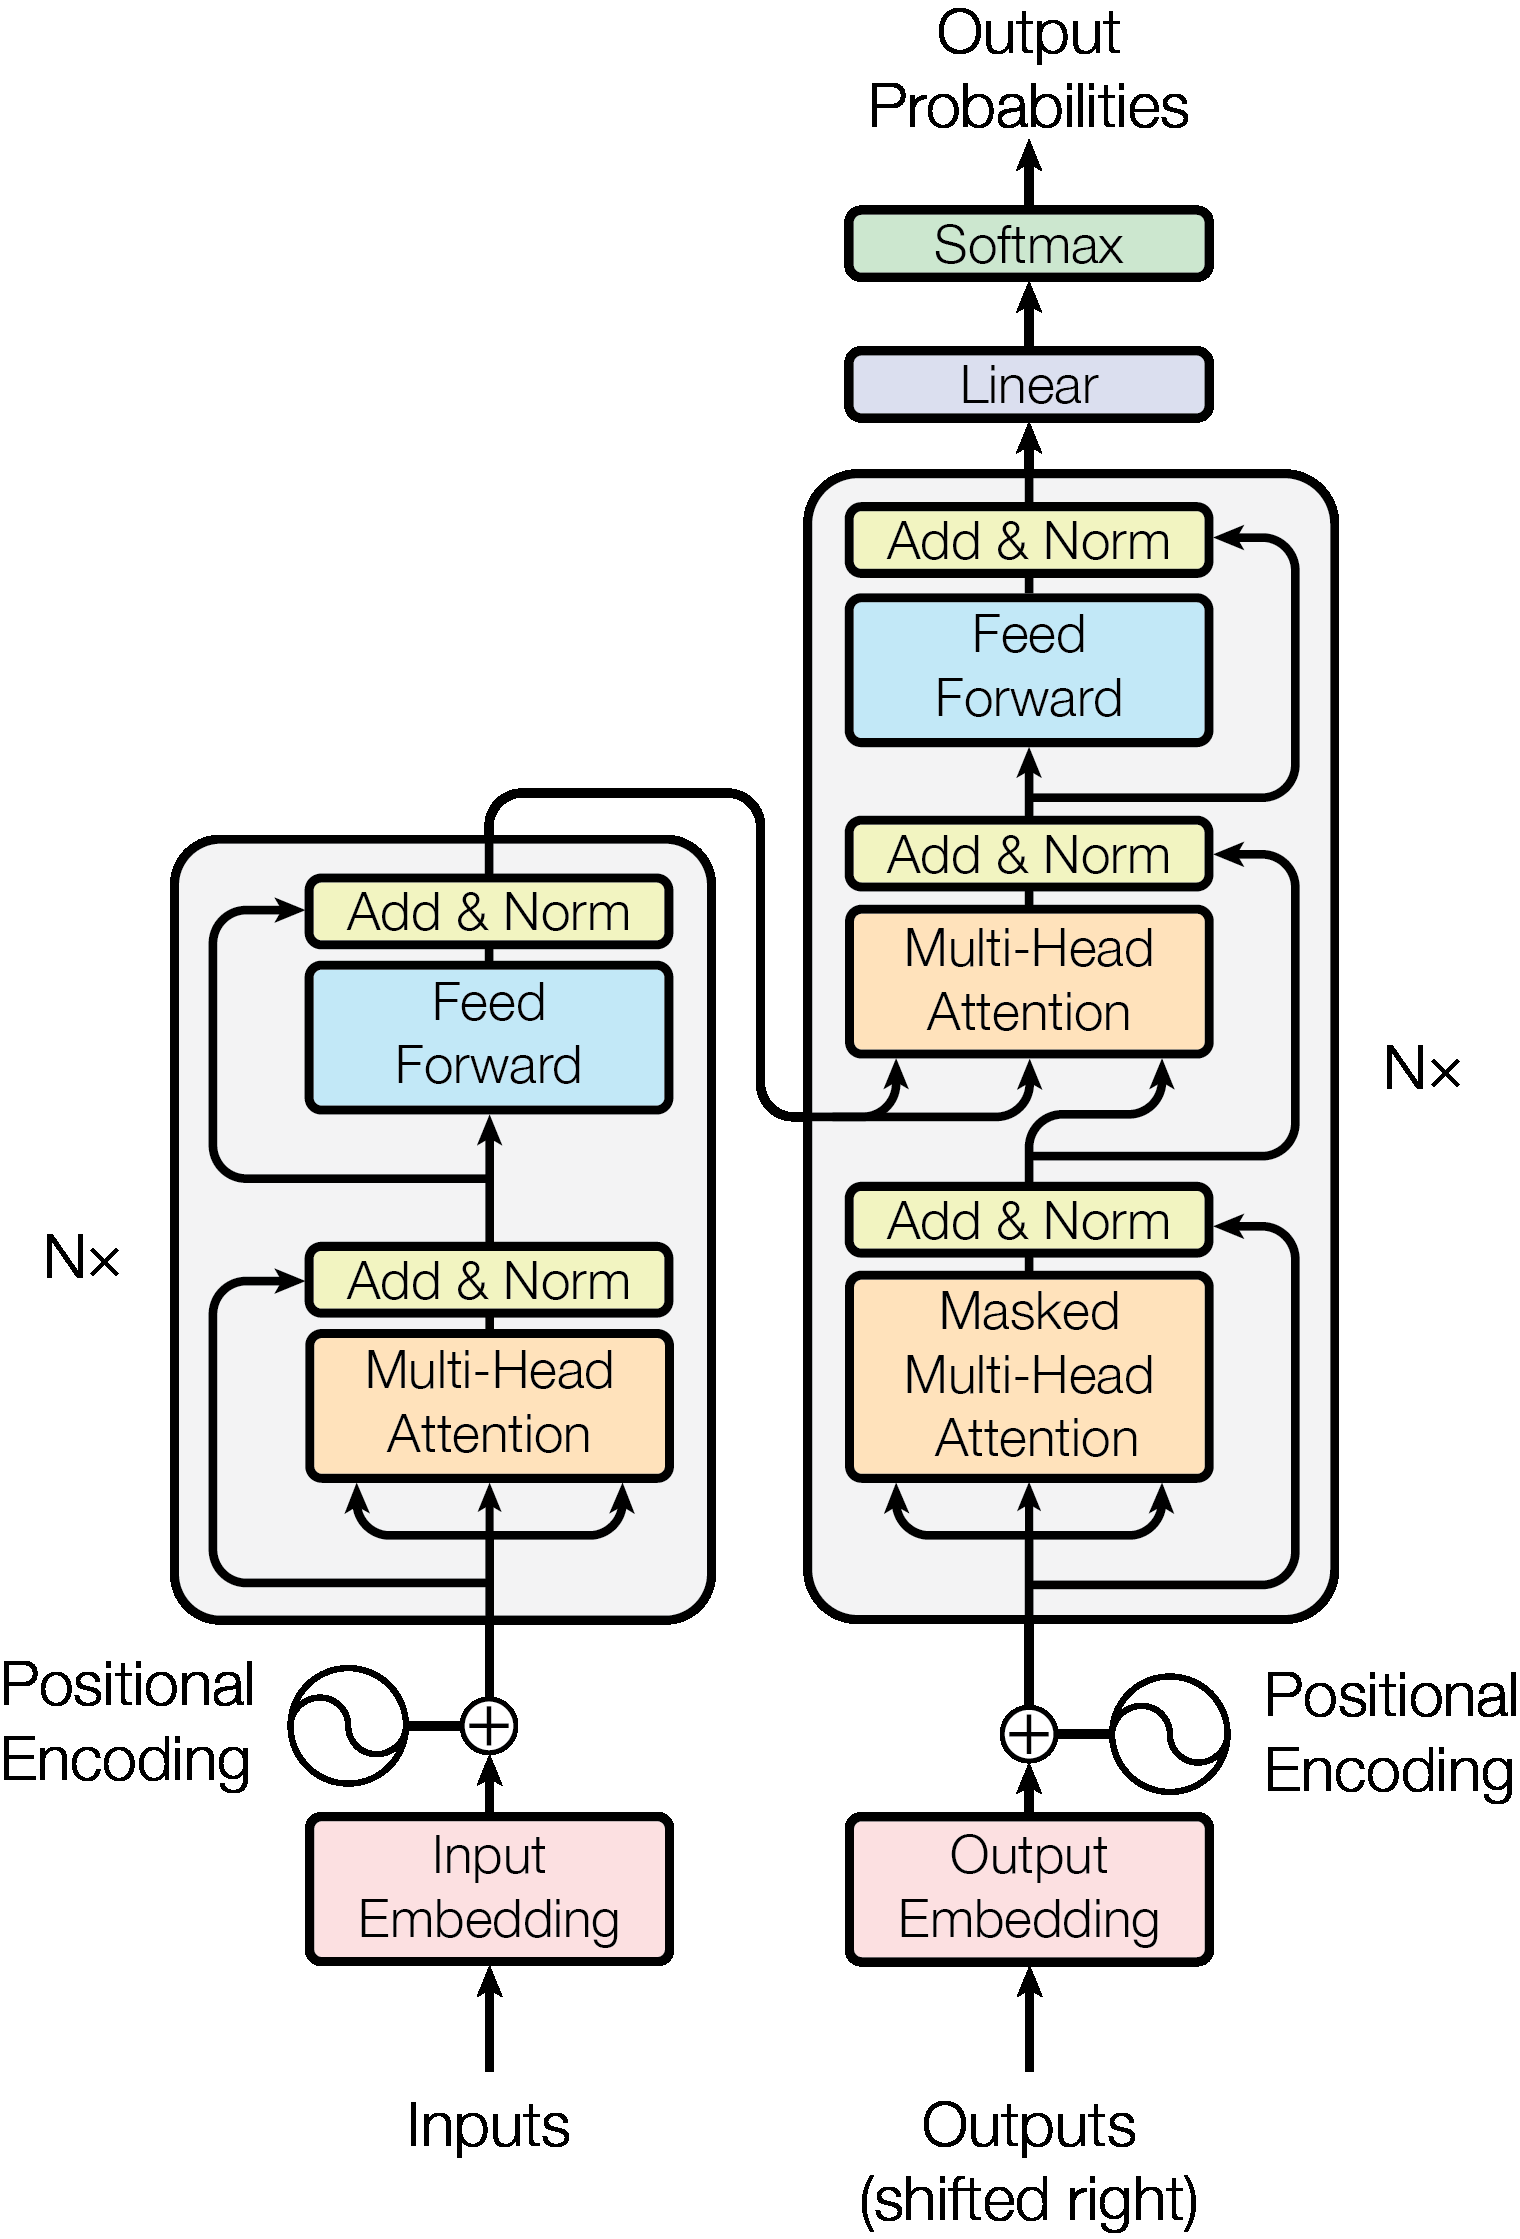

Image : page_003_image_94.png
Dimension : 512
5 premières valeurs : [0.030236879363656044, -0.1393793821334839, -0.0026145121082663536, -0.03246210142970085, 0.0024378132075071335]
Norme L2 : 1.000000004388652


In [30]:
#TESTER L'ENCODEUR D'IMAGES
from IPython.display import display

IMAGE_DIR = Path("resultats_pdf/images")

extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

images = sorted(
    fichier for fichier in IMAGE_DIR.iterdir()
    if fichier.is_file()
    and fichier.suffix.lower() in extensions
)

assert images, "Aucune image trouvée"

image_test = images[0]

with Image.open(image_test) as image:
    display(image.copy())

embedding_image_test = encoder_image(image_test)

print("Image :", image_test.name)

print("Dimension :", len(embedding_image_test))

print("5 premières valeurs :", embedding_image_test[:5])

print("Norme L2 :", np.linalg.norm(embedding_image_test))

In [31]:
#Vectorisation des textes par lots
BATCH_SIZE = 16

embeddings_textes = []

for debut in range(0, len(chunks_textes), BATCH_SIZE):

    lot = chunks_textes[debut:debut + BATCH_SIZE]

    textes_lot = [
        item["texte"] for item in lot
    ]

    vecteurs_lot = encoder_textes(textes_lot)

    embeddings_textes.extend(vecteurs_lot)

    print(
        f"Progression : "
        f"{len(embeddings_textes)}/{len(chunks_textes)}"
    )

print("\nVectorisation textuelle terminée.")

print("Nombre d'embeddings :", len(embeddings_textes))

Progression : 16/171
Progression : 32/171
Progression : 48/171
Progression : 64/171
Progression : 80/171
Progression : 96/171
Progression : 112/171
Progression : 128/171
Progression : 144/171
Progression : 160/171
Progression : 171/171

Vectorisation textuelle terminée.
Nombre d'embeddings : 171


In [33]:
#Vectorisation de toutes les images
donnees_images = []

for fichier in images:

    numero_page = int(fichier.stem.split("_")[1])

    embedding = encoder_image(fichier)

    donnees_images.append({
        "type": "image",
        "page": numero_page,
        "chemin": str(fichier),
        "embedding": embedding
    })

    print(f"Image vectorisée : {fichier.name}")

print("\nNombre d'images vectorisées :", len(donnees_images))

Image vectorisée : page_003_image_94.png
Image vectorisée : page_004_image_102.png
Image vectorisée : page_004_image_104.png

Nombre d'images vectorisées : 3


In [35]:
#Vérification de tous les embeddings
matrice_textes = np.array(
    embeddings_textes,
    dtype=np.float32
)

matrice_images = np.array(
    [item["embedding"] for item in donnees_images],
    dtype=np.float32
)

print("Dimensions des textes :", matrice_textes.shape)

print("Dimensions des images :", matrice_images.shape)

print("\nNormes des textes :")
print(np.linalg.norm(matrice_textes, axis=1)[:5])

print("\nNormes des images :")
print(np.linalg.norm(matrice_images, axis=1))

assert len(embeddings_textes) == len(chunks_textes)

assert matrice_textes.shape[1] == 512
assert matrice_images.shape[1] == 512

assert np.isfinite(matrice_textes).all()
assert np.isfinite(matrice_images).all()

assert np.allclose(
    np.linalg.norm(matrice_textes, axis=1),
    1,
    atol=1e-5
)

assert np.allclose(
    np.linalg.norm(matrice_images, axis=1),
    1,
    atol=1e-5
)

print("\nTous les embeddings sont valides et normalisés.")

Dimensions des textes : (171, 512)
Dimensions des images : (3, 512)

Normes des textes :
[1.         1.         0.99999994 1.         0.99999994]

Normes des images :
[1.         1.         0.99999994]

Tous les embeddings sont valides et normalisés.


In [36]:
#Premier test de similarité multimodale
matrice_textes = np.array(
    embeddings_textes,
    dtype=np.float32
)

matrice_images = np.array(
    [item["embedding"] for item in donnees_images],
    dtype=np.float32
)

print("Dimensions des textes :", matrice_textes.shape)

print("Dimensions des images :", matrice_images.shape)

print("\nNormes des textes :")
print(np.linalg.norm(matrice_textes, axis=1)[:5])

print("\nNormes des images :")
print(np.linalg.norm(matrice_images, axis=1))

assert len(embeddings_textes) == len(chunks_textes)

assert matrice_textes.shape[1] == 512
assert matrice_images.shape[1] == 512

assert np.isfinite(matrice_textes).all()
assert np.isfinite(matrice_images).all()

assert np.allclose(
    np.linalg.norm(matrice_textes, axis=1),
    1,
    atol=1e-5
)

assert np.allclose(
    np.linalg.norm(matrice_images, axis=1),
    1,
    atol=1e-5
)

print("\nTous les embeddings sont valides et normalisés.")

Dimensions des textes : (171, 512)
Dimensions des images : (3, 512)

Normes des textes :
[1.         1.         0.99999994 1.         0.99999994]

Normes des images :
[1.         1.         0.99999994]

Tous les embeddings sont valides et normalisés.
